In [1]:
import os
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
gdrive_dir = '/content/drive/'
drive.mount(gdrive_dir, force_remount=True)

pd.set_option('display.max_rows',None)
warnings.filterwarnings('ignore')

Mounted at /content/drive/


In [2]:
df=pd.read_csv('/content/drive/MyDrive/ВШЭ/годовой проект/dataset.csv')

In [3]:
df['target']=df['QH WAP']
df['timestamp']=pd.to_datetime(df['timestamp'])
df.drop(columns=['QH WAP'],inplace=True)
df=df.sort_values('timestamp').copy()

In [4]:
df['timestamp'].duplicated().any()

np.False_

In [5]:
df.duplicated().any()

np.False_

В датасете пропусков строк (по датам) нет, дубликатов в целом и по датам в частности тоже нет

In [6]:
df.isna().sum()

,0
timestamp,0
demand_forecast_mwh,0
wind_forecast_mwh,0
solar_forecast_mwh,0
nuclear_forecast_mwh,0
temperature_forecast_c,0
net_exchange_forecast_mwh,0
target,94


In [7]:
df['slot']=df['timestamp'].dt.hour*4+df['timestamp'].dt.minute//15

median_7d=(df.groupby('slot')['target'].transform(lambda x: x.shift(1).rolling(7, min_periods=1).median()))
df['target']=df['target'].fillna(median_7d)
df.drop(columns=['slot'],inplace=True)

Пропуски были в таргете, заполнены медианой последних 14 дней таких же 15 минуток. Такое решение было принято вместо удаления, для сохранения непрерывной временной структуры и для более удобного и четкого построения лаговых признаков.

Общее распределение

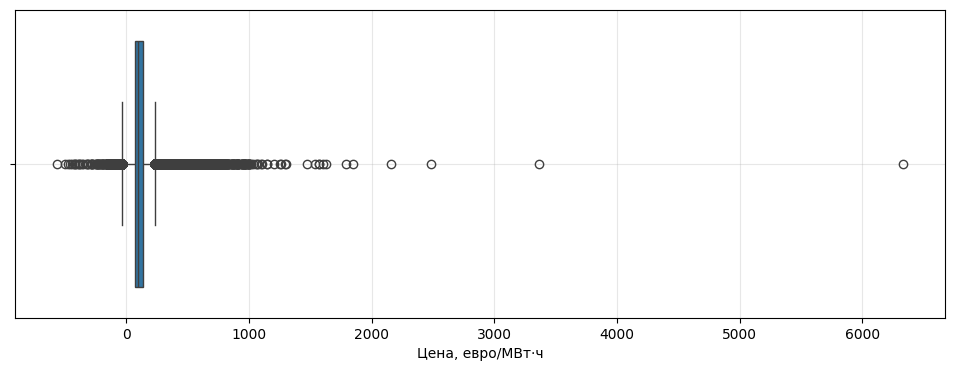

In [8]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['target'])
plt.xlabel('Цена, евро/МВт·ч')
plt.grid(alpha=0.3)
plt.show()

Распределение положительных цен

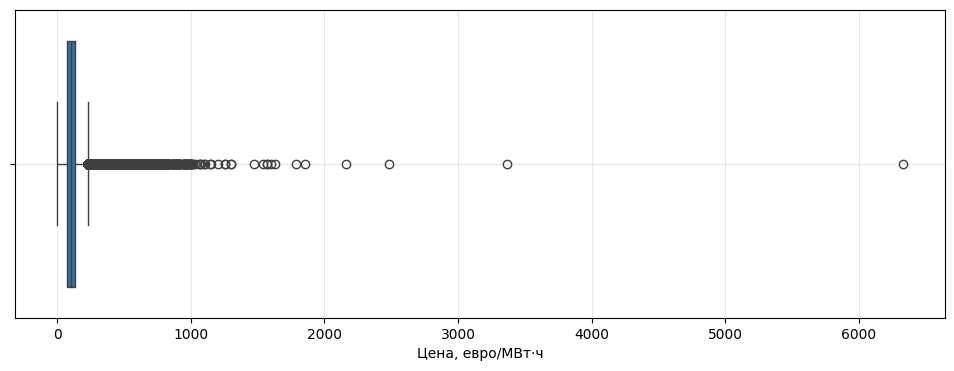

In [9]:
pos_target=df[df['target']>=0].reset_index(drop=True)
plt.figure(figsize=(12, 4))
sns.boxplot(x=pos_target['target'])
plt.xlabel('Цена, евро/МВт·ч')
plt.grid(alpha=0.3)
plt.show()

Распределение отрицательных цен

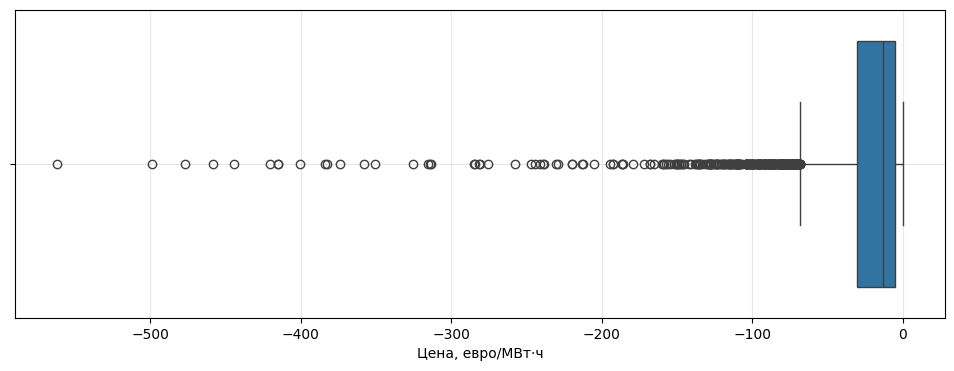

In [10]:
neg_target=df[df['target']<0].reset_index(drop=True)
plt.figure(figsize=(12, 4))
sns.boxplot(x=neg_target['target'])
plt.xlabel('Цена, евро/МВт·ч')
plt.grid(alpha=0.3)
plt.show()

In [11]:
neg_q05=neg_target['target'].quantile(0.05)
print("5 квантиль отрицательных значений",np.round(neg_q05,2))
pos_q95=pos_target['target'].quantile(0.95)
print("95 квантиль положительных значений",np.round(pos_q95,2))
q01=df['target'].quantile(0.01)
q05=df['target'].quantile(0.05)
q95=df['target'].quantile(0.95)
q99=df['target'].quantile(0.99)
print("1 квантиль:", np.round(q01,2))
print("5 квантиль:", np.round(q05,2))
print("95 квантиль:", np.round(q95,2))
print("99 квантиль:", np.round(q99,2))

5 квантиль отрицательных значений -85.54
95 квантиль положительных значений 224.5
1 квантиль: -29.51
5 квантиль: 5.37
95 квантиль: 222.13
99 квантиль: 377.66


In [12]:
df['target']=df['target'].clip(neg_q05,pos_q95)

В качестве обрезки выбросов принято решение разделить датасет на сэмплы с положительным и отрицательным таргетом, взять соотвественно нижний 5% квантиль у отрицательных и 95% у положительных. Поскольку присутсвует "хвост" в сторону больших значений и в случае выбора обрезки по 5-95 квантилям сэмплы с отрицательными значениями пропадают, что отнимает у модели часть предметной области. А обрезка по 1-99 квантилям оставляет достаточно выбросов с большими значениями и также существенно затрагивает сэмплы с отрицательными значениями

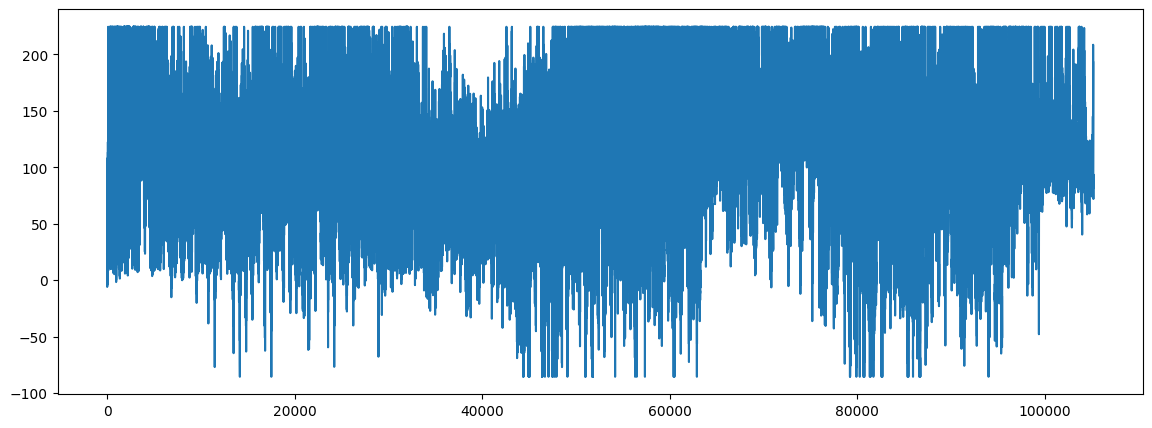

In [13]:
plt.figure(figsize=(14,5))
plt.plot(df['target'])
plt.show()

Для лучшей визуализации ряда построим графики с помощью медианного фильтра и скользящего среднего

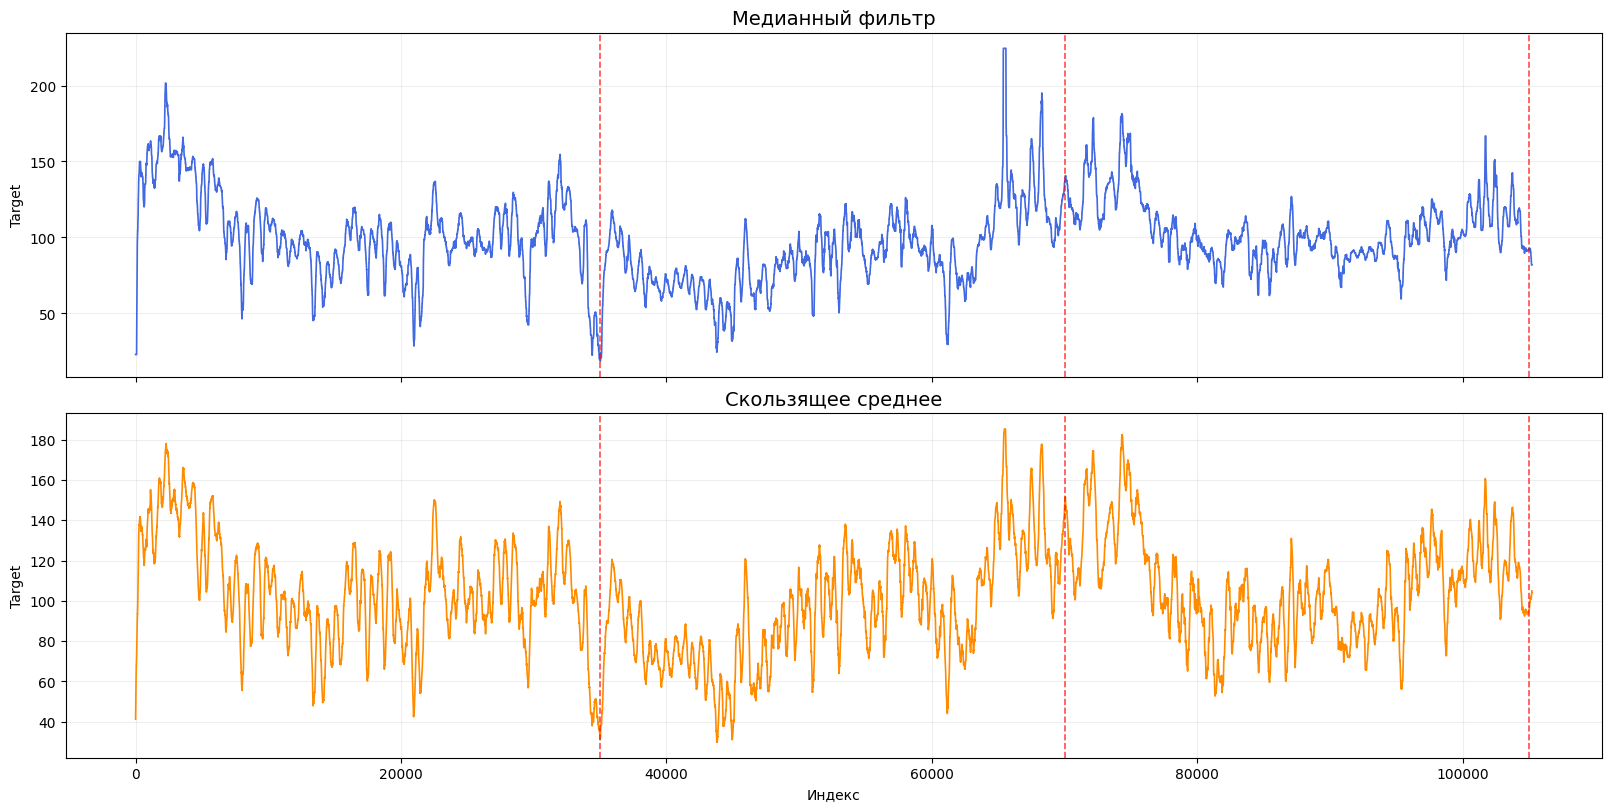

In [14]:
from scipy.ndimage import median_filter

y = df['target']
window = 288 #сглаживание по 3 дням

y_median = median_filter(y.to_numpy(), size=window, mode='nearest')
y_mean = y.rolling(window=window, center=True, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True, constrained_layout=True)

axes[0].plot(y.index, y_median, color='royalblue', linewidth=1.2)
axes[0].set_title('Медианный фильтр', fontsize=14)
axes[0].set_ylabel('Target')
axes[0].grid(alpha=0.2)

axes[1].plot(y.index, y_mean, color='darkorange', linewidth=1.2)
axes[1].set_title('Скользящее среднее', fontsize=14)
axes[1].set_xlabel('Индекс')
axes[1].set_ylabel('Target')
axes[1].grid(alpha=0.2)

for ax in axes:
    for i in range(35000, len(y), 35000):
        ax.axvline(y.index[i], color='red', linestyle='--', linewidth=1.2, alpha=0.7)
plt.show()

Проверим сезонность, построим автокорреляцию

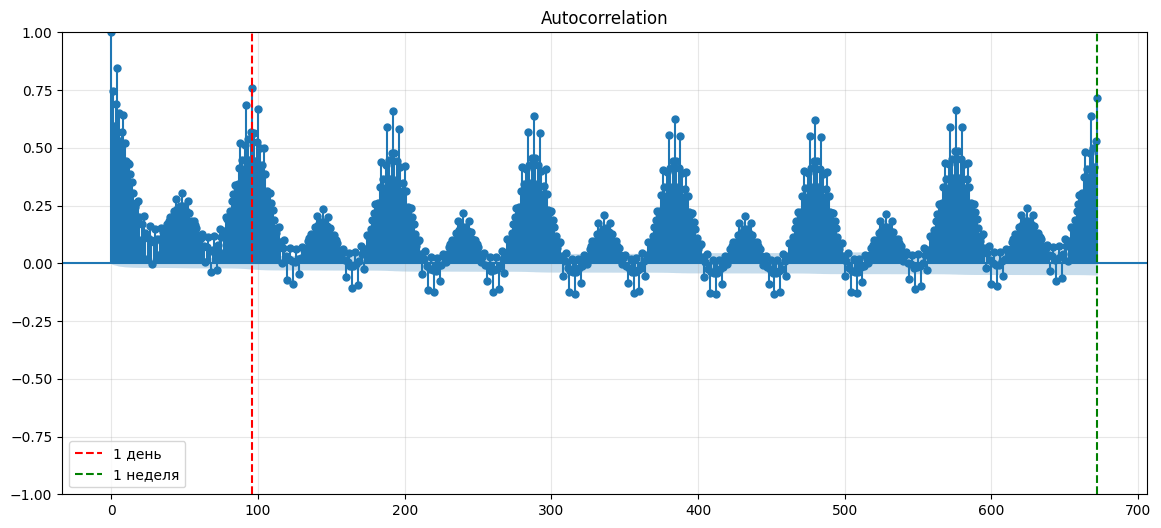

In [15]:
from statsmodels.graphics.tsaplots import plot_acf

y=df['target']
fig,ax=plt.subplots(figsize=(14,6))
plot_acf(y,lags=672,fft=True,alpha=0.05,ax=ax)
ax.axvline(96,color='red',ls='--',label='1 день')
ax.axvline(672,color='green',ls='--',label='1 неделя')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Из acf видно, что присутствует ежедневная, 12 и немного 6 часовая сезонность. Также стоит проверить на большем интервале времени месячную и недельную сезонность

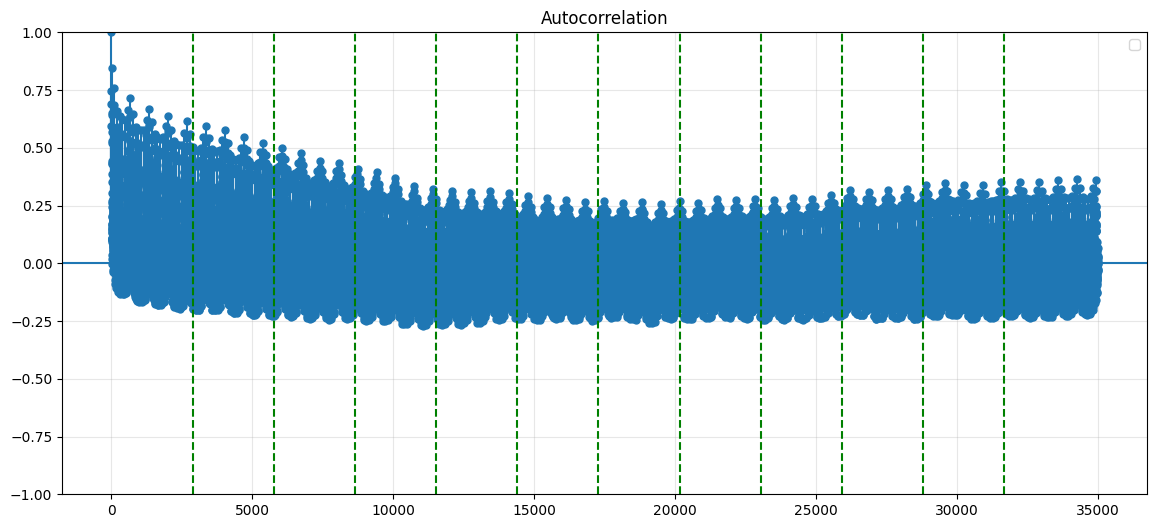

In [16]:
fig,ax=plt.subplots(figsize=(14,6))
plot_acf(y,lags=35000,fft=True,alpha=0.05,ax=ax)
for i in range(1,12):
  ax.axvline(2880*i,color='green',ls='--')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Из автокорреляции видно, что выраженной месячной сезонности не наблюдается, а вот внутри зеленых линий (месяцов) заметна уже недельная сезонность

Таким образом, из acf можно сделать вывод, что у ряда наблюдается недельная (672 точки), суточная (96 точек), 12-часовая (48 точек) и 6-часовая (24 точки) сезонности

Для определения близких лагов таргета построим коррелограмму на ближайшие 3 дня

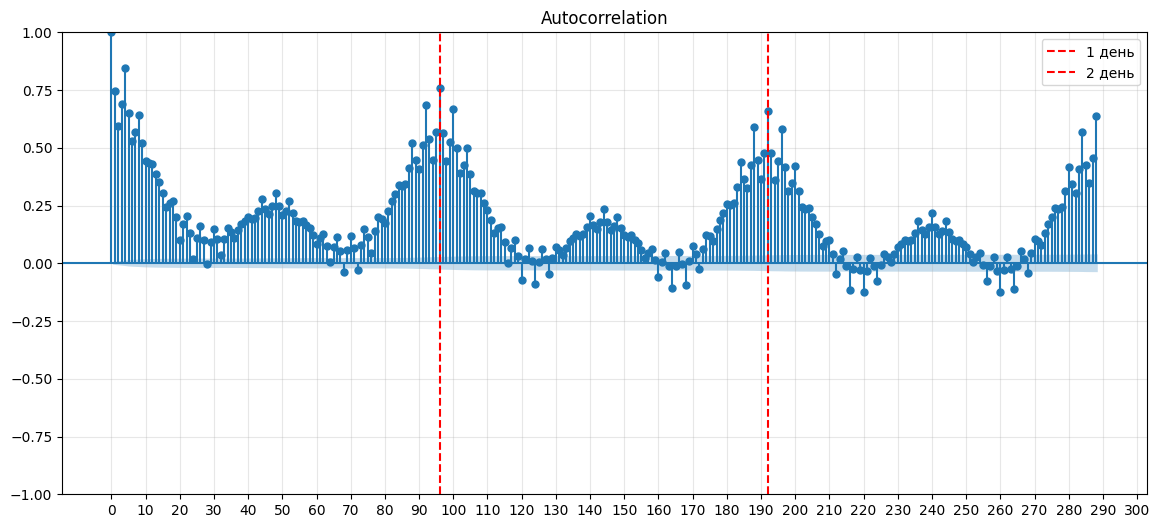

In [44]:
fig,ax=plt.subplots(figsize=(14,6))
plot_acf(y,lags=288,fft=True,alpha=0.05,ax=ax)
ax.axvline(96,color='red',ls='--',label='1 день')
ax.axvline(192,color='red',ls='--',label='2 день')
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(np.arange(0, 301, 10))
plt.show()

В качестве лагов ближайших дней были взяты 1-9, 48, 88-104, 124, 144, 164, 184-200, 220, 240, 260, 280-296, 672 (недельная сезонность). Скользящие средние с окном 24, 48, 96, 192 начиная с предыдущих суток

In [23]:
lags = [*range(1, 10), 48, *range(88,105), 124, 144, 164, *range(184, 201), 220, 240, 260, *range(280, 297), 672]
windows = [24, 48, 96, 192]

position=df['timestamp'].dt.hour*4+df['timestamp'].dt.minute//15+1

for lag in lags:
    df[f'lag_{lag}'] = df['target'].shift(lag)
    if lag < 96:
        df[f'lag_{lag}'] = df[f'lag_{lag}'].mask(position > lag)

for window in windows:
    df[f'rolling_mean_{window}'] = df['target'].shift(96).rolling(window).mean()

Удалим первые 672 строки, чтобы убрать сэмплы с большим количеством пропусков из-за построения лагов

In [24]:
df=df.iloc[672:].reset_index(drop=True)

Добавим календарные признаки по венгерскому времени: месяц, день недели, час, номер 15-минутки внутри дня, флаг праздника/выходного страны Венгрия

In [25]:
import holidays

ts=df["timestamp"].dt.tz_convert("Europe/Budapest")

df['month']=ts.dt.month
df['day_of_week']=ts.dt.dayofweek
df['day_of_month']=ts.dt.day
df['hour']=ts.dt.hour
df['quarter_hour']=ts.dt.hour*4+ts.dt.minute//15

hu_holidays=holidays.country_holidays('HU',years=ts.dt.year.unique().tolist())
df['is_weekend_holiday']=((ts.dt.dayofweek>=5)|ts.dt.date.isin(hu_holidays)).astype('int')

Проверим распределение значений признаков

Признак demand_forecast_mwh


,Значение,"Доля, %"
0,4456.1,0.01
1,5023.7,0.01
2,4998.3,0.01
3,4845.9,0.01
4,4687.6,0.01


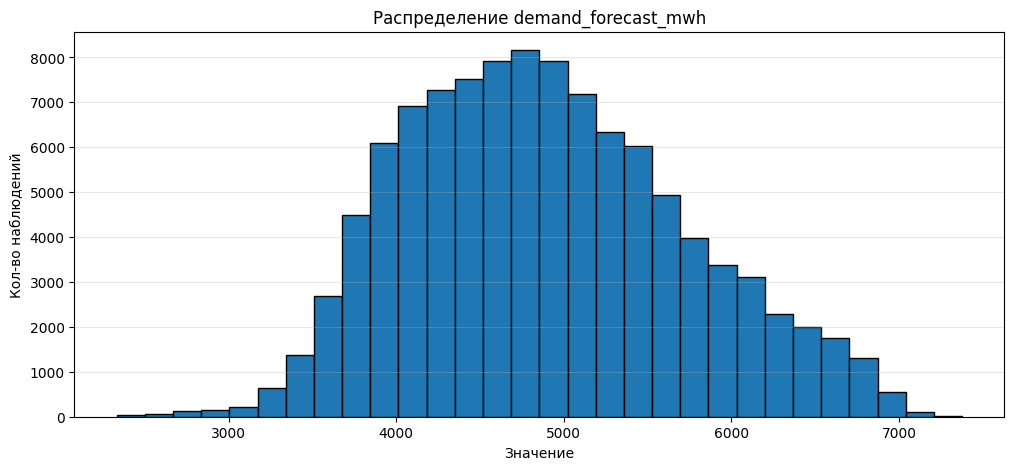

Признак wind_forecast_mwh


,Значение,"Доля, %"
0,6.7,0.26
1,5.7,0.26
2,6.6,0.25
3,5.0,0.25
4,7.0,0.25


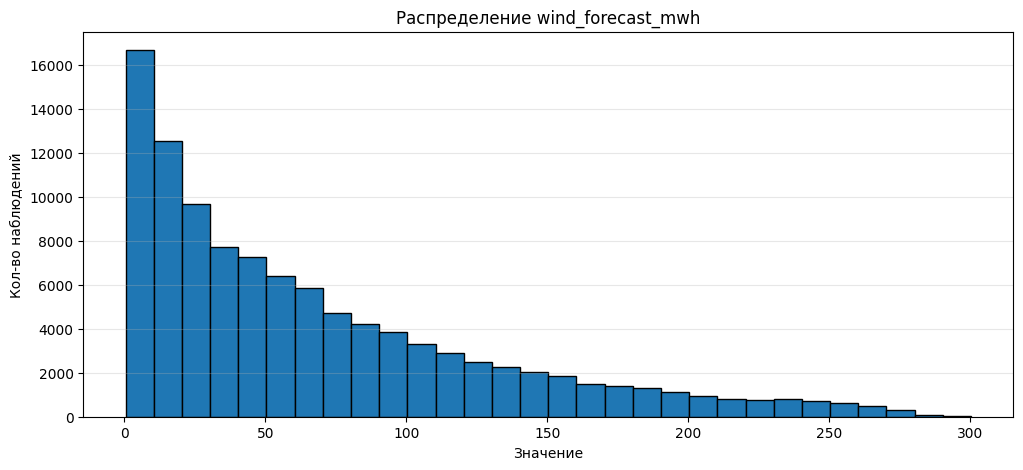

Признак solar_forecast_mwh


,Значение,"Доля, %"
0,0.0,47.52
1,0.1,0.15
2,0.2,0.10
3,0.3,0.07
4,0.6,0.06


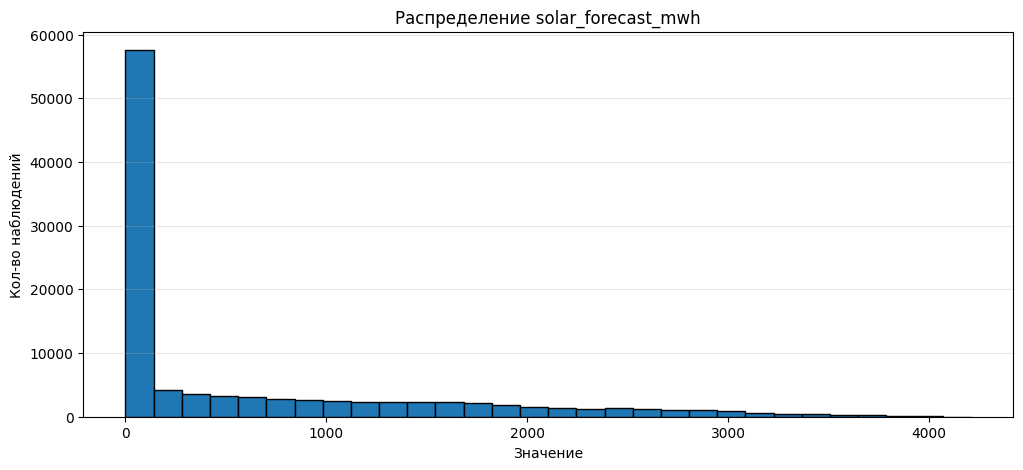

Признак nuclear_forecast_mwh


,Значение,"Доля, %"
0,1900.0,54.09
1,1428.0,14.20
2,1920.0,9.63
3,1440.0,7.53
4,1422.0,5.59


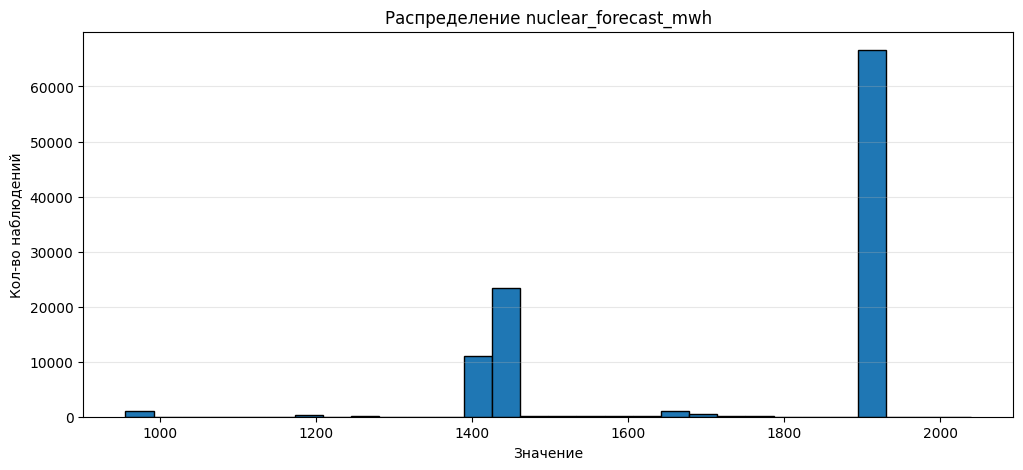

Признак temperature_forecast_c


,Значение,"Доля, %"
0,15.04,0.06
1,2.64,0.06
2,3.13,0.05
3,2.54,0.05
4,3.47,0.05


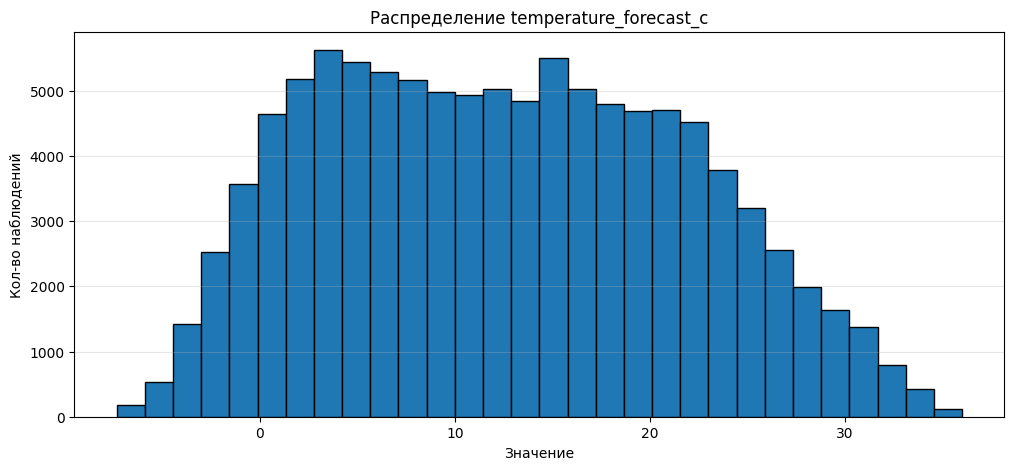

Признак net_exchange_forecast_mwh


,Значение,"Доля, %"
0,-600.0,3.05
1,-200.0,2.27
2,-1900.0,0.96
3,-1200.0,0.72
4,-2900.0,0.72


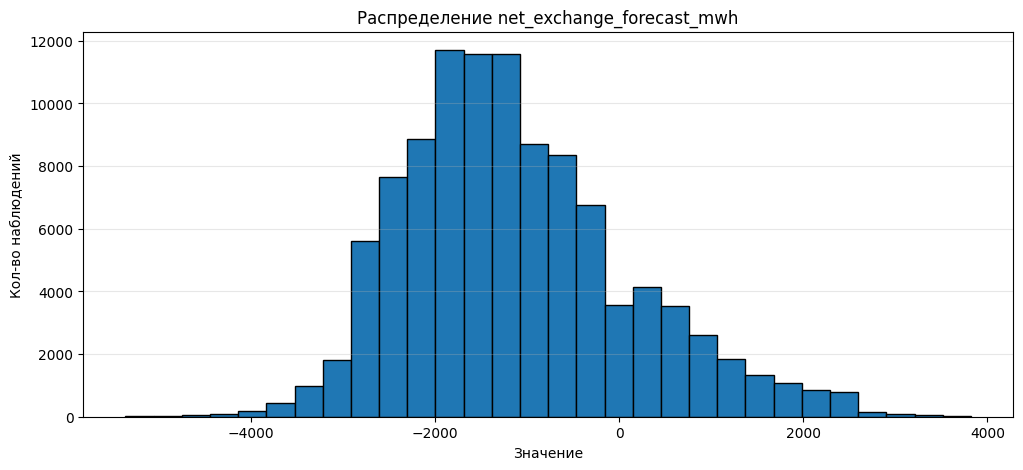

In [26]:
features=['demand_forecast_mwh','wind_forecast_mwh','solar_forecast_mwh','nuclear_forecast_mwh','temperature_forecast_c','net_exchange_forecast_mwh']
for feat in features:
   print(f'Признак {feat}')
   top5 = (df[feat].value_counts(normalize=True).head(5).mul(100).round(2).reset_index())
   top5.columns = ['Значение', 'Доля, %']
   display(top5)
   plt.figure(figsize=(12, 5))
   plt.hist(df[feat], bins=30, edgecolor='black')
   plt.title(f'Распределение {feat}')
   plt.xlabel('Значение')
   plt.ylabel('Кол-во наблюдений')
   plt.grid(axis='y', alpha=0.3)
   plt.show()

Для будущей модели бустинга признаки можно не преобразовывать, а для линейных моделей стоит еще предобработать некоторые

In [65]:
df_boosting=df.copy()
df_linear=df.copy()

df_linear=df_linear.drop(columns=[f'lag_{lag}' for lag in lags if lag < 96])

К wind_forecast_mwh стоит применить np.log1p, чтобы убрать перекос

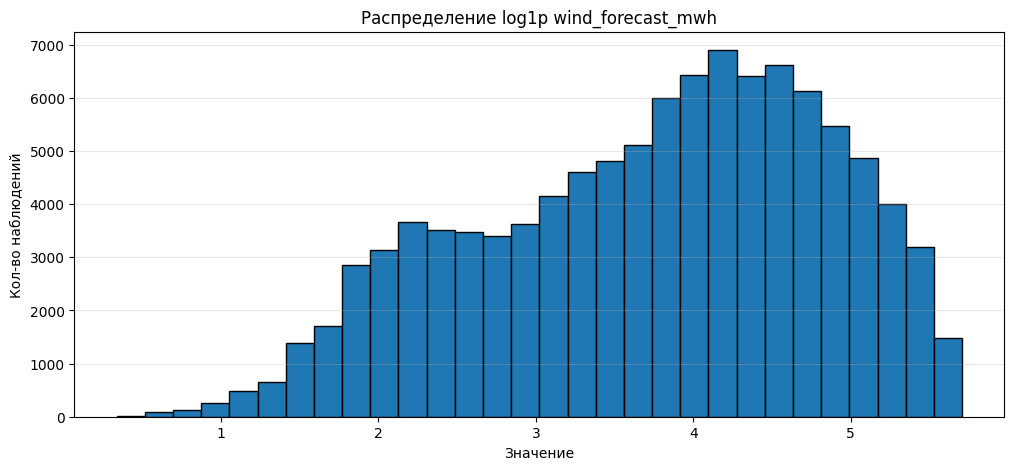

In [66]:
df_linear['wind_forecast_mwh']=np.log1p(df_linear['wind_forecast_mwh'])

plt.figure(figsize=(12, 5))
plt.hist(df_linear['wind_forecast_mwh'], bins=30, edgecolor='black')
plt.title(f'Распределение log1p wind_forecast_mwh')
plt.xlabel('Значение')
plt.ylabel('Кол-во наблюдений')
plt.grid(axis='y', alpha=0.3)
plt.show()

У признака nuclear_forecast_mwh распределение выглядит практически дискретным: 64% сэмплов это значения (1900,1920), 32.5% это значения (1422, 1424, 1428, 1440, 1442), и 3.5% остальные значения. Поэтому из этого признака можно сделать несколько категориальных. Повышенная выработка (1900 и 1920), среднее (менее 1900, но больше 1400) и остальное- пониженное

In [67]:
top10 = (df_linear['nuclear_forecast_mwh'].value_counts(normalize=True).head(10).mul(100).round(2).reset_index())
top10.columns = ['Значение', 'Доля, %']
display(top10)

,Значение,"Доля, %"
0,1900.0,54.09
1,1428.0,14.20
2,1920.0,9.63
3,1440.0,7.53
4,1422.0,5.59
5,1424.0,4.87
6,956.0,1.01
7,1442.0,0.53
8,1680.0,0.49
9,1660.0,0.46


In [68]:
df_linear['nuclear_high']=df_linear['nuclear_forecast_mwh'].isin([1900, 1920]).astype(int)
df_linear['nuclear_medium']=df_linear['nuclear_forecast_mwh'].between(1400, 1900, inclusive='neither').astype(int)
#nuclear_low не добавляем чтобы не создавать линейной зависимости
df_linear.drop(columns=['nuclear_forecast_mwh'],inplace=True)

Для получившихся признаков для датасета под линейные модели, кроме флагов перед обучением будем применять RobustScaler, чтобы у некоторых признаков убрать хвосты

Проверим мультиколлинеарность признаков

По результатам vif, стоит убрать hour, nuclear_high, rolling_mean_48, rolling_mean_96, rolling_mean_192, lag_101, lag_102, lag_103 lag_189, lag_190, lag_191, lag_193, lag_194, lag_195, lag_196, lag_284, lag_289, lag_290, lag_291 из датасета под линейные модели

In [69]:
cols=['hour', 'nuclear_high', 'rolling_mean_48', 'rolling_mean_96', 'rolling_mean_192', 'lag_101', 'lag_102',
      'lag_103', 'lag_189', 'lag_190', 'lag_191', 'lag_193', 'lag_194', 'lag_195', 'lag_196', 'lag_284', 'lag_289', 'lag_290', 'lag_291']
df_linear.drop(columns=cols,inplace=True)

In [70]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X=df_linear.drop(columns=['target', 'timestamp'])
X=sm.add_constant(X)
vif=pd.DataFrame({'feature':X.columns,'VIF':[variance_inflation_factor(X.values,i) for i in range(X.shape[1])]})
vif=vif[vif['feature']!='const'].sort_values('VIF', ascending=False)
print(vif)

                      feature        VIF
10                    lag_100  10.060772
36                    lag_292   9.828015
29                    lag_281   9.685020
30                    lag_282   9.612247
35                    lag_288   9.553537
34                    lag_287   9.392855
33                    lag_286   9.381386
19                    lag_188   9.345640
31                    lag_283   8.793407
23                    lag_199   8.497741
22                    lag_198   8.480865
32                    lag_285   8.471871
39                    lag_295   8.417905
6                      lag_96   8.347144
38                    lag_294   8.325673
37                    lag_293   8.270363
17                    lag_186   8.072524
20                    lag_192   8.070235
16                    lag_185   8.060064
40                    lag_296   8.012132
9                      lag_99   7.947208
18                    lag_187   7.942323
11                    lag_104   7.897601
42            ro

# Вывод
В данных отсутсвуют дубликаты, временной ряд непрерывный (нет пропусков в наблюдениях), также отсутсвуют резкие изменения формы ряда или другие структурные изменения.

Пропуски присутсвуют только в таргете, заполнены медианной по окну соответсвующих предыдущих наблюдений. В таргете присутсвуют выбросы, было принято решение обрезать их по квантилям: снизу 5% отрицательных значений и сверху 95% положительных значений.

Построена коррелограмма (acf) таргета со своими лагами и выявлены несколько сезонностей: недельная, суточная, 12-часовая, 6-часовая. На ее основе составлены лаговые признаки и скользящие средние по таргету.

Были добавлены календарные признаки, основываясь на времени Будапешта: месяц, день месяца, день недели, номер 15-минутки внутри суток, а также флаг выходных и гос. праздников Венгрии.

В дополнительных признаках (данных изначально) распределение стремится к нормальному (где-то с хвостами), кроме wind_forecast_mwh, nuclear_forecast_mwh и solar_forecast_mwh. К wind_forecast_mwh применен безопасный логарифм. nuclear_forecast_mwh преобразован в категориальный и сделан one-hot encoding.

На основе получившегося датасета был выбран датасет под будующие линейные модели. С признаками без пропусков и дальнейшим отбором с помощью анализа их мультиколлинеарности. Были отобраны признаки с vif<10.1

